# Dataset v1 · Resolution experiment evaluation

Compare frozen Model V1 (640 px), EXP-01 (960 px), and EXP-02 (1280 px) at their respective resolutions using the same CPU and the same images. The comparison measures training and inference resolution together. The historical 640 px model trained on CPU, while both higher-resolution models train on MPS.

### Model V1 evaluation audit

Notebook 05 evaluated validation and test AP using Ultralytics 8.4.218 on CPU at 640 px, batch 4, workers 0, rectangular batching, confidence floor 0.001, and NMS IoU 0.70. Standard precision and recall were reported at the library's best-F1 point. The deployment threshold maximized interpolated validation F2, breaking ties by higher recall and then lower confidence. V1 froze the threshold at 71/999. Test prediction used batch 1, NMS IoU 0.70 and that frozen threshold, with confidence-ordered matching at IoU 0.50.

Here, AP uses the same low confidence floor. Reported test precision, recall, and F2 use the validation-locked operating points. Timing measures the mean and median forward pass in ms/image after a full warmup pass, with batch 1 and common CPU settings.

In [2]:
import hashlib
import json
import platform
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import pandas as pd
import torch
import ultralytics
import yaml
from IPython.display import display
from ultralytics import YOLO

root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "notebooks/05_model_v1_training.ipynb").is_file()
)
runs = root / "data/dataset_v1/runs/resolution_experiments"
report_dir = runs / "evaluation"
frozen = root / "models/model_v1"
models = {
    "Model V1": (640, frozen / "best.pt"),
    "EXP-01": (960, runs / "EXP-01/weights/best.pt"),
    "EXP-02": (1280, runs / "EXP-02/weights/best.pt"),
}
ap_config = dict(device="cpu", batch=4, workers=0, conf=0.001, iou=0.7, rect=True)
match_iou = 0.5

def digest(path: Path) -> str:
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

def evaluation_inputs() -> tuple[Path, dict]:
    for name in ("EXP-01", "EXP-02"):
        if not (runs / name / "training_complete").is_file():
            raise FileNotFoundError(f"Complete {name} in notebook 07 first.")
        manifest = runs / name / "experiment.yaml"
        recorded_version = yaml.safe_load(manifest.read_text())["ultralytics"]
        if recorded_version != ultralytics.__version__:
            raise RuntimeError(f"Use Ultralytics {recorded_version} to match {name}.")
    baseline = json.loads((frozen / "baseline.json").read_text())
    if digest(models["Model V1"][1]) != baseline["sha256"]:
        raise ValueError("Model V1 checkpoint differs from the frozen baseline.")
    data = runs / "EXP-01/dataset/data.yaml"
    return data, baseline

def ap_metrics(weights: Path, size: int, data: Path, split: str, name: str, plots: bool):
    # Use the same experiment-local dataset for all three evaluations.
    return YOLO(str(weights)).val(
        data=str(data), split=split, imgsz=size, plots=plots,
        project=str(report_dir / name), name=split, exist_ok=True, **ap_config,
    )

## 1. Lock operating points on validation

The experiment checkpoints were already selected by validation fitness during training. Run this stage to tune each experiment's threshold using validation only. V1 keeps its previously selected validation threshold. Compare validation results before opening the test stage.

In [4]:
def choose_threshold(metrics) -> tuple[float, pd.DataFrame]:
    curves = {
        ylabel: (x, y[0]) for x, y, xlabel, ylabel in metrics.curves_results
        if xlabel == "Confidence" and ylabel in {"Precision", "Recall"}
    }
    confidence, precision = curves["Precision"]
    _, recall = curves["Recall"]
    table = pd.DataFrame(dict(confidence=confidence, precision=precision, recall=recall))
    table = table.loc[table.confidence >= ap_config["conf"]].copy()
    denominator = 4 * table.precision + table.recall
    table["F2"] = (5 * table.precision * table.recall / denominator.where(denominator > 0)).fillna(0)
    best = table.sort_values(["F2", "recall", "confidence"], ascending=[False, False, True]).iloc[0]
    return float(best.confidence), table

run_validation = True
if run_validation:
    data, baseline = evaluation_inputs()
    operating_points = {}
    validation_rows = []
    for name, (size, weights) in models.items():
        metrics = ap_metrics(weights, size, data, "val", name, plots=True)
        threshold, curve = choose_threshold(metrics)
        if name == "Model V1":
            threshold = baseline["confidence"]
        curve.to_csv(report_dir / name / "validation_thresholds.csv", index=False)
        operating_points[name] = dict(confidence=threshold, imgsz=size, sha256=digest(weights))
        validation_rows.append(dict(
            model=name, imgsz=size, confidence=threshold, precision=metrics.box.mp,
            recall=metrics.box.mr, mAP50=metrics.box.map50, mAP50_95=metrics.box.map,
        ))
    validation_summary = pd.DataFrame(validation_rows)
    validation_summary.to_csv(report_dir / "validation_metrics.csv", index=False)
    (report_dir / "operating_points.json").write_text(json.dumps(operating_points, indent=2) + "\n")
    display(validation_summary.round(4))

Ultralytics 8.4.219 🚀 Python-3.12.16 torch-2.15.0 CPU (Apple M2)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.1 ms, read: 260.3±35.3 MB/s, size: 71.8 KB)
val: Scanning /Users/aarishtickoo/workspace/traffic-pii-masking/data/dataset_v1/runs/resolution_experiments/EXP-01/dataset/labels/val.cache... 17 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 2.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 5.3it/s 0.9s0.3s
                   all         17         15      0.881      0.992      0.984      0.857
Speed: 0.5ms preprocess, 42.6ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /Users/aarishtickoo/workspace/traffic-pii-masking/data/dataset_v1/runs/resolution_experiments/evaluation/Model V1/val
Ultralytics 8.4.219 🚀 Python-3.12.16 torch-2.15.0 CPU (Apple M2)
YOLO11n summary (fused): 101 layers, 2,597,051 para

,model,imgsz,confidence,precision,recall,mAP50,mAP50_95
0,Model V1,640,0.0711,0.8814,0.9915,0.9837,0.8571
1,EXP-01,960,0.3413,0.8810,0.9880,0.9745,0.8816
2,EXP-02,1280,0.7277,0.9772,1.0000,1.0000,0.8758


## 2. Final held-out test

Enable this cell after accepting the validation operating points. Evaluate every model on the same 15 test images. Count matches in descending confidence order with one ground-truth match per detection, as in notebook 05.

In [5]:
def load_targets(path: Path, width: int, height: int) -> list[tuple[int, tuple]]:
    targets = []
    for line in path.read_text().splitlines():
        if line.strip():
            cls, cx, cy, w, h = map(float, line.split())
            targets.append((int(cls), (
                (cx - w / 2) * width, (cy - h / 2) * height,
                (cx + w / 2) * width, (cy + h / 2) * height,
            )))
    return targets

def box_iou(a, b) -> float:
    x1, y1, x2, y2 = a
    u1, v1, u2, v2 = b
    overlap = max(0, min(x2, u2) - max(x1, u1)) * max(0, min(y2, v2) - max(y1, v1))
    union = (x2 - x1) * (y2 - y1) + (u2 - u1) * (v2 - v1) - overlap
    return overlap / union if union > 0 else 0.0

def match_counts(result, targets: list) -> tuple[int, int, int]:
    predictions = sorted(
        zip(result.boxes.conf.tolist(), result.boxes.cls.tolist(), result.boxes.xyxy.tolist()),
        key=lambda prediction: prediction[0], reverse=True,
    )
    available = set(range(len(targets)))
    for _, cls, box in predictions:
        overlap, index = max(
            ((box_iou(box, targets[i][1]), i) for i in available if cls == targets[i][0]),
            default=(0.0, -1),
        )
        if overlap >= match_iou:
            available.remove(index)
    tp = len(targets) - len(available)
    return tp, len(predictions) - tp, len(available)

In [6]:
run_test = True
test_predictions = {}
if run_test:
    data, _ = evaluation_inputs()
    operating_points = json.loads((report_dir / "operating_points.json").read_text())
    for name, (size, weights) in models.items():
        point = operating_points[name]
        if point["imgsz"] != size or point["sha256"] != digest(weights):
            raise ValueError(f"{name} checkpoint or resolution changed after validation.")

    dataset = yaml.safe_load(data.read_text())
    test_dir = data.parent / dataset["test"]
    images = sorted(test_dir.glob("*.jpg"))
    if len(images) != 15:
        raise ValueError("Expected 15 held-out Dataset v1 images.")
    labels = data.parent / "labels/test"
    rows = []
    for name, (size, weights) in models.items():
        metrics = ap_metrics(weights, size, data, "test", name, plots=False)
        conf = operating_points[name]["confidence"]
        model = YOLO(str(weights))
        predict_config = dict(
            imgsz=size, device="cpu", batch=1, conf=conf, iou=ap_config["iou"],
            rect=True, verbose=False, save=False,
        )
        # One path per call guarantees batch 1 in the predictor.
        for path in images:
            model.predict(source=str(path), **predict_config)
        results = [model.predict(source=str(path), **predict_config)[0] for path in images]
        if [Path(result.path).name for result in results] != [p.name for p in images]:
            raise RuntimeError(f"{name} predictions differ from the shared test image order.")
        test_predictions[name] = results

        counts = []
        for result in results:
            h, w = result.orig_shape
            label = labels / Path(result.path).with_suffix(".txt").name
            counts.append(match_counts(result, load_targets(label, w, h)))
        tp, fp, fn = map(sum, zip(*counts))
        latency = pd.DataFrame([result.speed for result in results])
        latency.insert(0, "image", [path.name for path in images])
        latency.to_csv(report_dir / name / "test_latency.csv", index=False)
        row = dict(
            model=name, imgsz=size, confidence=conf, tp=tp, fp=fp, fn=fn,
            precision=tp / (tp + fp) if tp + fp else 0.0,
            recall=tp / (tp + fn) if tp + fn else 0.0,
            F2=5 * tp / (5 * tp + 4 * fn + fp) if tp + fn + fp else 0.0,
            mAP50=metrics.box.map50, mAP50_95=metrics.box.map,
            inference_mean_ms=latency.inference.mean(),
            inference_median_ms=latency.inference.median(),
        )
        pd.DataFrame([row]).to_csv(report_dir / name / "test_metrics.csv", index=False)
        rows.append(row)
    comparison = pd.DataFrame(rows).set_index("model")
    comparison.to_csv(report_dir / "test_comparison.csv")
    settings = dict(ap=ap_config, match_iou=match_iou, predict_batch=1, warmup_passes=1,
                    platform=platform.platform(), torch=str(torch.__version__),
                    ultralytics=ultralytics.__version__, operating_points=operating_points)
    (report_dir / "test_settings.json").write_text(json.dumps(settings, indent=2) + "\n")
    display(comparison.round(4))

Ultralytics 8.4.219 🚀 Python-3.12.16 torch-2.15.0 CPU (Apple M2)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.1 ms, read: 194.0±73.0 MB/s, size: 68.3 KB)
val: Scanning /Users/aarishtickoo/workspace/traffic-pii-masking/data/dataset_v1/runs/resolution_experiments/EXP-01/dataset/labels/test... 15 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 15/15 908.0it/s 0.0s
val: New cache created: /Users/aarishtickoo/workspace/traffic-pii-masking/data/dataset_v1/runs/resolution_experiments/EXP-01/dataset/labels/test.cache


Python(74082) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 4.5it/s 0.9s0.3s
                   all         15         16      0.931      0.938       0.97      0.784
Speed: 0.6ms preprocess, 50.7ms inference, 0.0ms loss, 0.9ms postprocess per image
Ultralytics 8.4.219 🚀 Python-3.12.16 torch-2.15.0 CPU (Apple M2)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2468.0±445.8 MB/s, size: 75.3 KB)
val: Scanning /Users/aarishtickoo/workspace/traffic-pii-masking/data/dataset_v1/runs/resolution_experiments/EXP-01/dataset/labels/test.cache... 15 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 15/15 5.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.7it/s 1.5s0.6s
                   all         15         16      0.875          1      0.965      0.771
Speed: 1.6ms preprocess, 88.2m

,imgsz,confidence,tp,fp,fn,precision,recall,F2,mAP50,mAP50_95,inference_mean_ms,inference_median_ms
model,,,,,,,,,,,,
Model V1,640,0.0711,16,4,0,0.8000,1.0,0.9524,0.9699,0.7837,43.5721,42.6311
EXP-01,960,0.3413,16,5,0,0.7619,1.0,0.9412,0.9648,0.7707,77.3406,75.6727
EXP-02,1280,0.7277,16,4,0,0.8000,1.0,0.9524,0.9778,0.8181,157.4301,151.5194


## 3. Compare detections on identical images

Each row shows ground truth and predictions from all three checkpoints on one test image. Start with the first five in filename order, then change the slice to inspect the remaining images. Keep the displayed images local and clear image outputs before sharing the notebook.

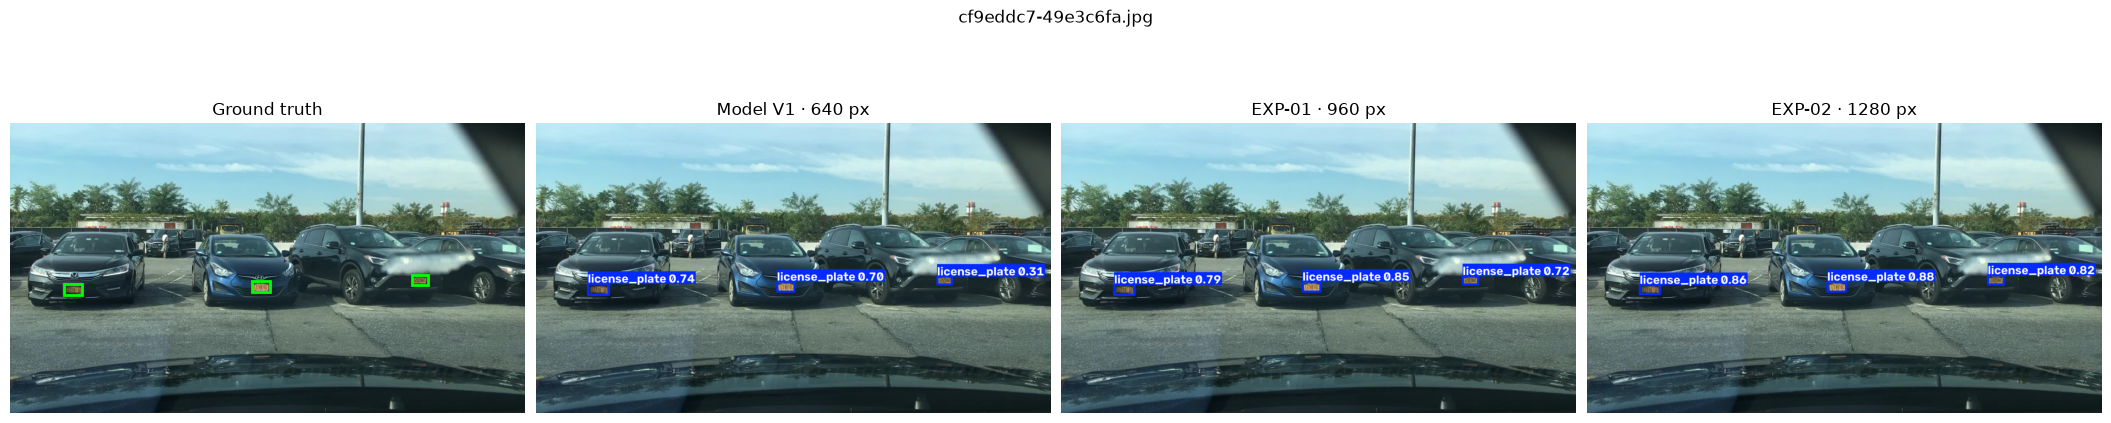

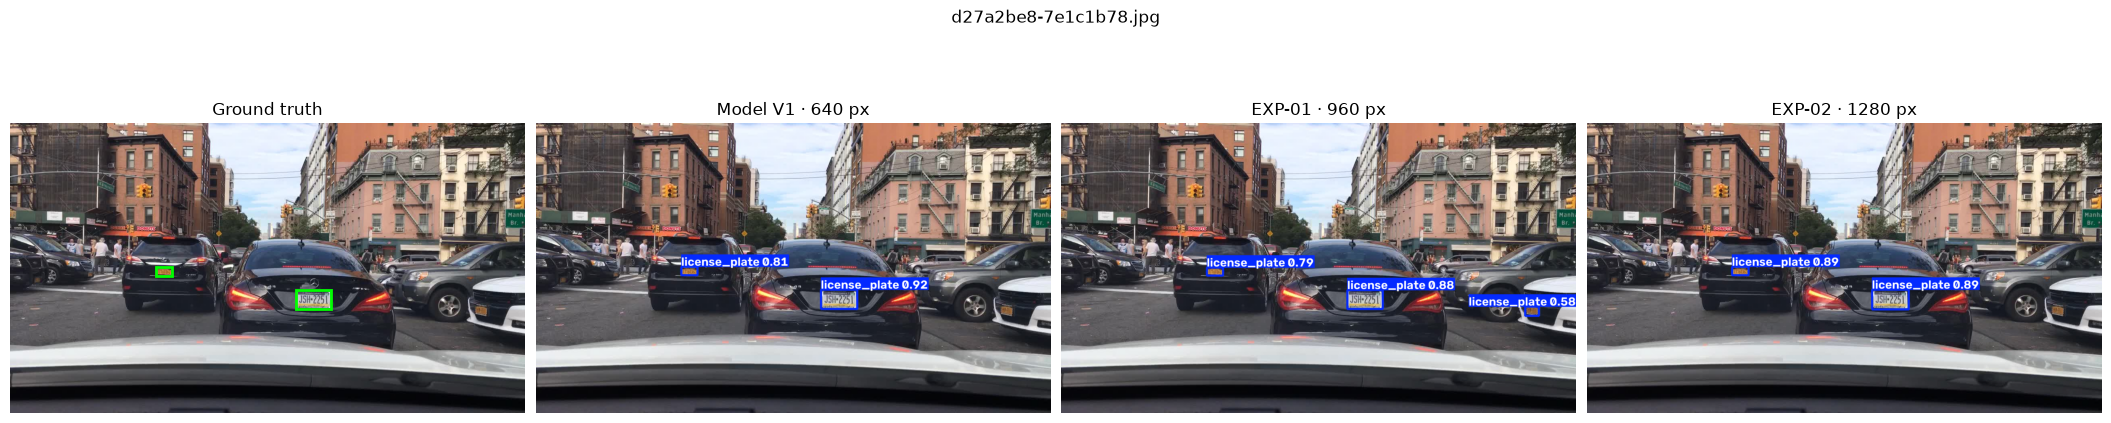

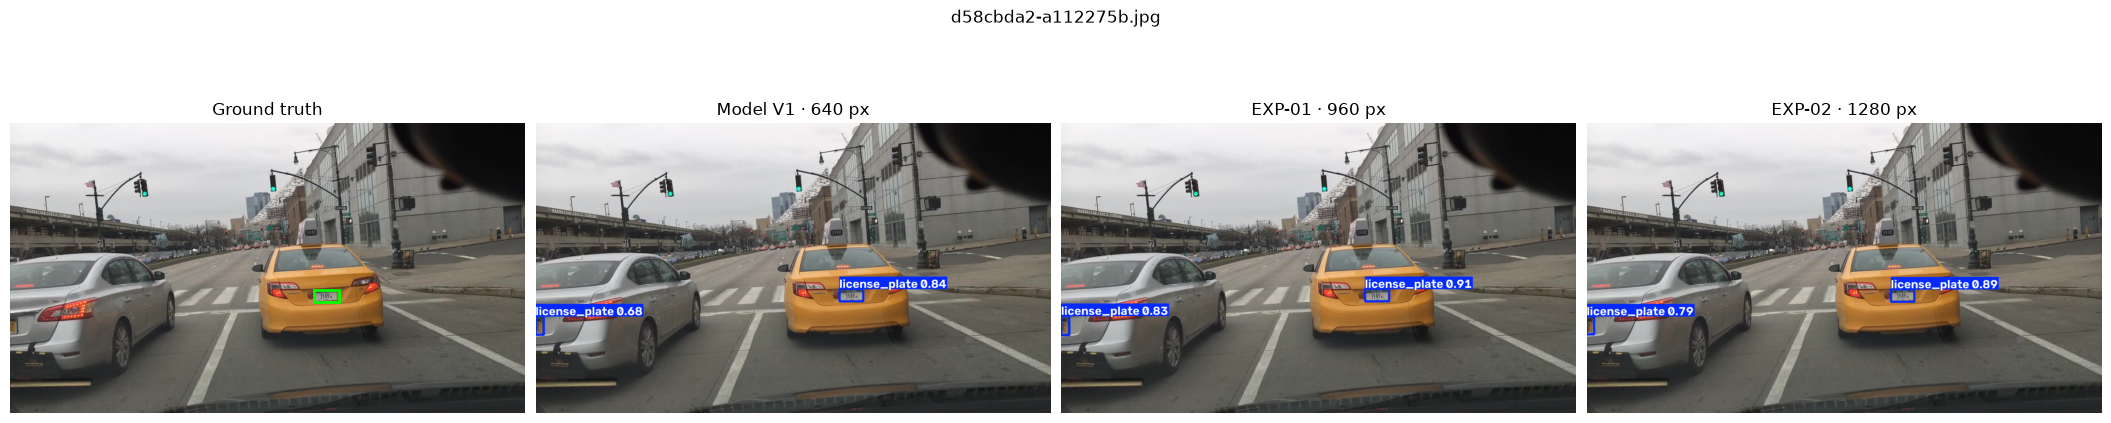

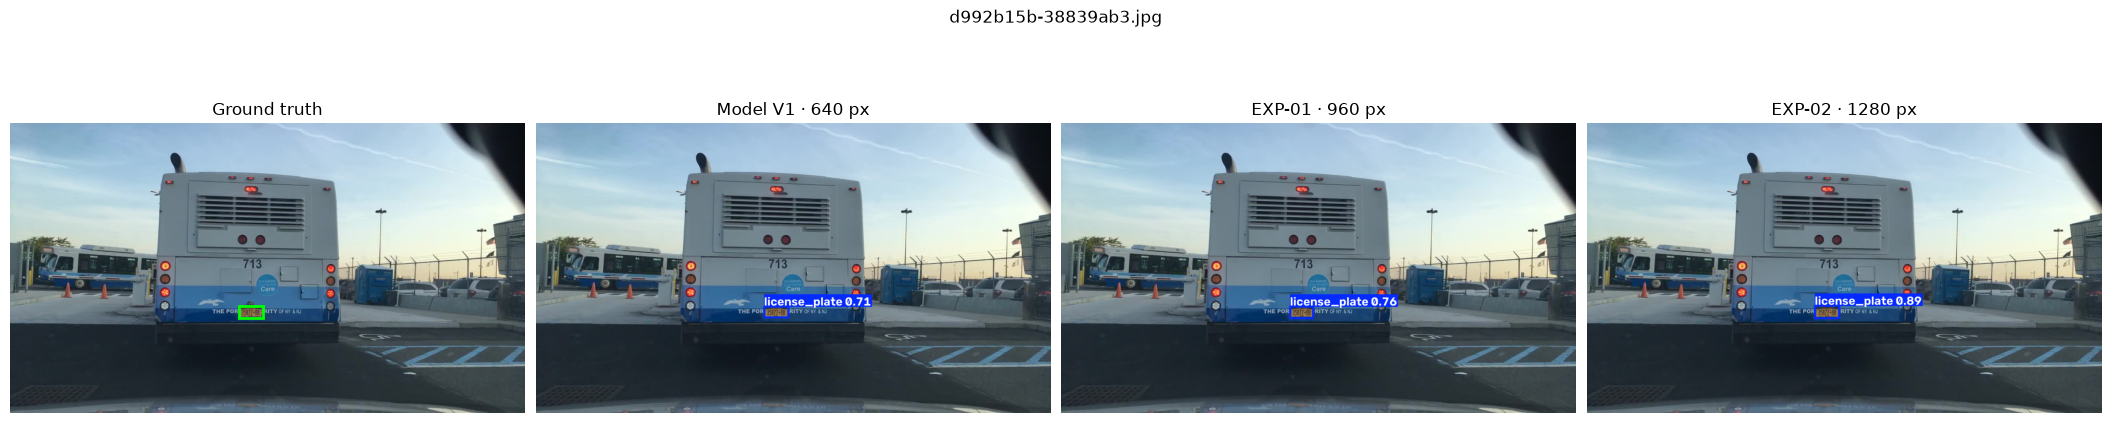

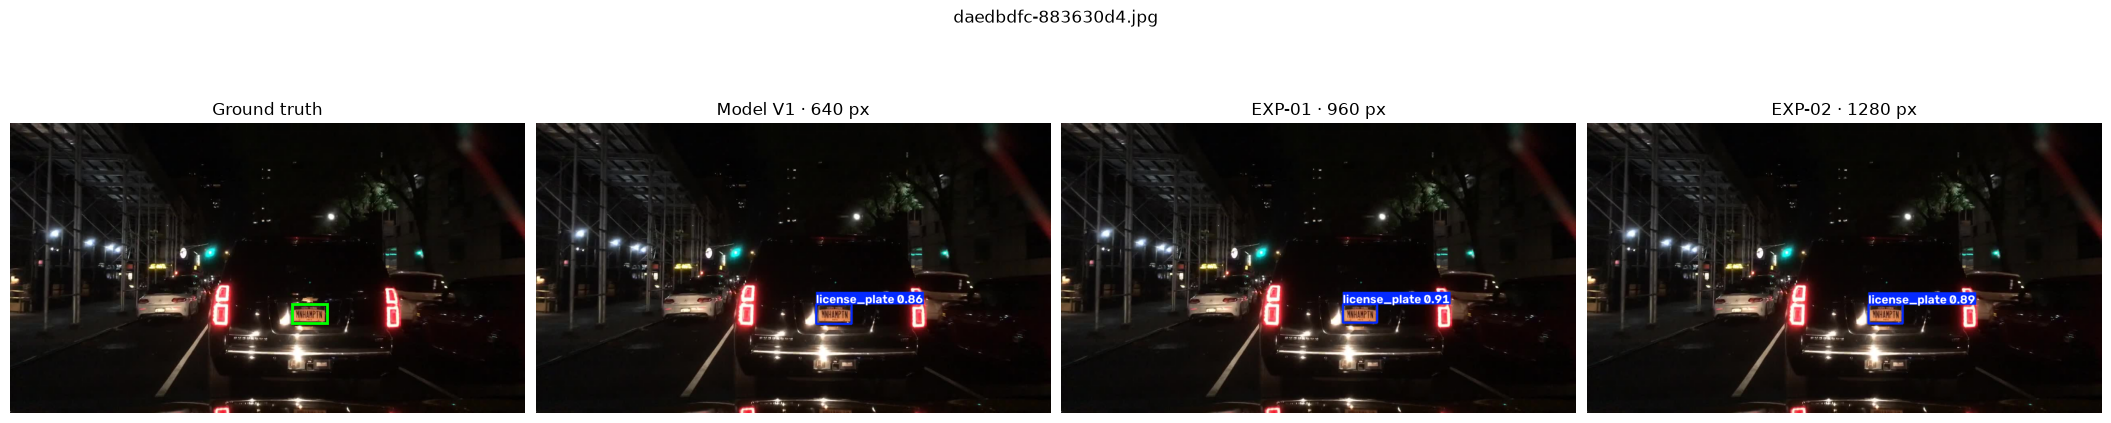

In [7]:
if test_predictions:
    for index in range(len(images))[:5]:
        image_path = images[index]
        reference = test_predictions["Model V1"][index]
        h, w = reference.orig_shape
        fig, axes = plt.subplots(1, 4, figsize=(21, 5), layout="constrained")
        axes[0].imshow(reference.orig_img[:, :, ::-1])
        axes[0].set_title("Ground truth")
        for _, (x1, y1, x2, y2) in load_targets(labels / image_path.with_suffix(".txt").name, w, h):
            axes[0].add_patch(Rectangle(
                (x1, y1), x2 - x1, y2 - y1, edgecolor="lime", fill=False, linewidth=2,
            ))
        for ax, (name, results) in zip(axes[1:], test_predictions.items()):
            ax.imshow(results[index].plot()[:, :, ::-1])
            ax.set_title(f"{name} · {models[name][0]} px")
        for ax in axes:
            ax.set_axis_off()
        fig.suptitle(image_path.name)
        plt.show()
        plt.close(fig)